
=== Rolling Forecast ARIMA ===


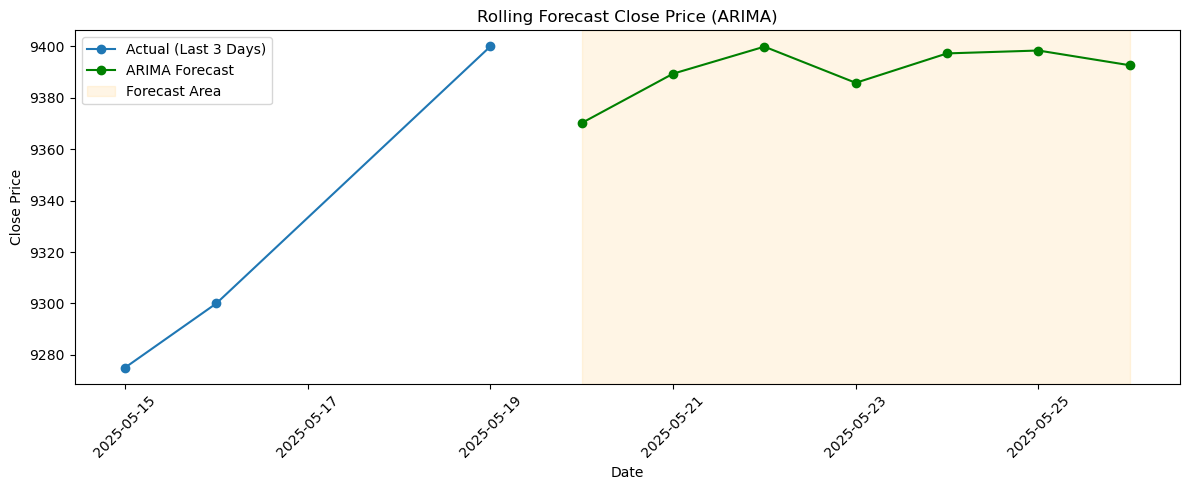

[ARIMA Rolling] MAPE: 2.28%, R²: -1.744

=== Rolling Forecast Prophet ===


13:56:42 - cmdstanpy - INFO - Chain [1] start processing
13:56:42 - cmdstanpy - INFO - Chain [1] done processing


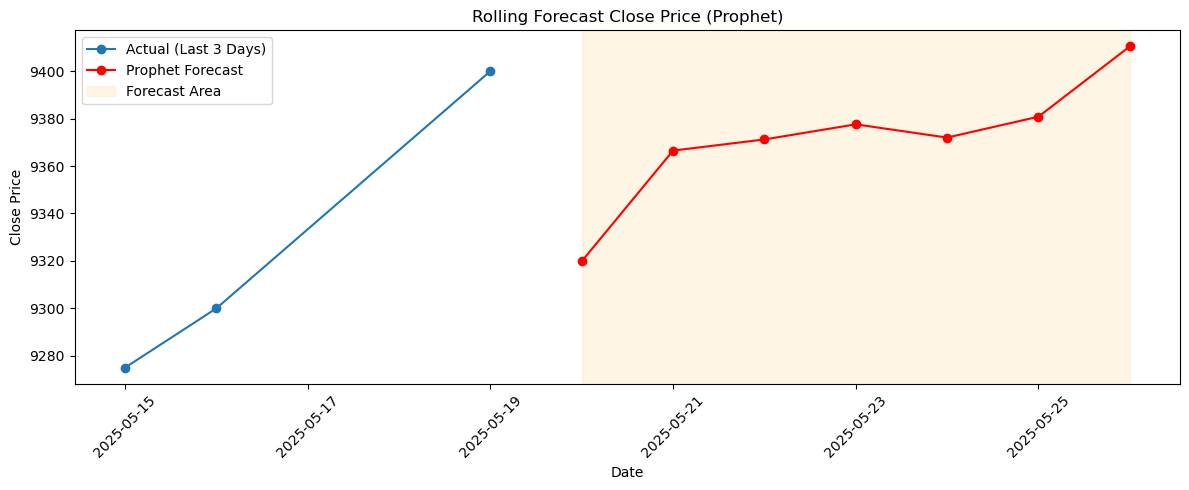

[Prophet Rolling] MAPE: 2.05%, R²: -1.273


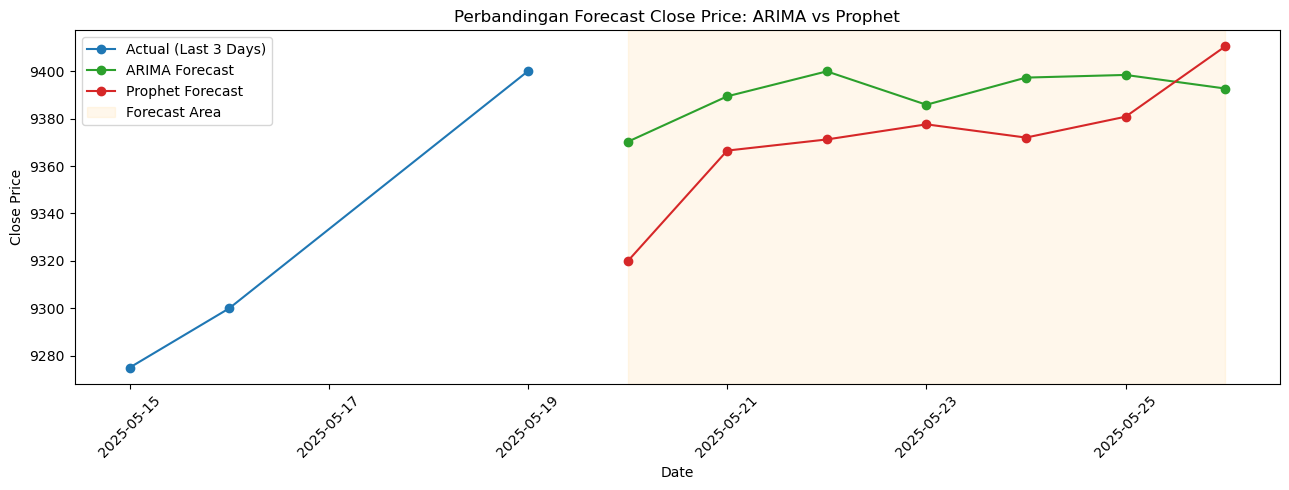

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score
import warnings

warnings.filterwarnings('ignore')

# -------------------------
# 1. Web Scraping (Yahoo Finance)
# -------------------------
from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.chrome.options import Options

chrome_driver_path = "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 3/final_ds/chromedriver-mac-arm64/chromedriver"
options = Options()
options.add_argument("--headless=new")
options.add_argument("--disable-gpu")
options.add_argument("--no-sandbox")
options.add_argument("--disable-dev-shm-usage")
service = Service(chrome_driver_path)
driver = webdriver.Chrome(service=service, options=options)
driver.get("https://finance.yahoo.com/quote/BBCA.JK/history/")

table = WebDriverWait(driver, 10).until(
    EC.presence_of_element_located((By.CLASS_NAME, "table"))
)
rows = table.find_elements(By.TAG_NAME, "tr")

data = []
for row in rows:
    cols = row.find_elements(By.TAG_NAME, "td")
    if len(cols) == 7:
        date = cols[0].text 
        open = cols[1].text
        high = cols[2].text 
        low = cols[3].text  
        close = cols[4].text
        adj_close = cols[5].text  
        volume = cols[6].text  
        data.append([date, open, high, low, close, adj_close, volume])

df = pd.DataFrame(data, columns=["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"])
driver.quit()

# -------------------------
# 2. Preprocessing Data
# -------------------------
def preprocess_data(df_raw):
    df = df_raw.copy()
    df['Date'] = df['Date'].astype(str)
    df = df[df['Date'].str.match(r'^[A-Za-z]{3,} \d{1,2}, \d{4}$', na=False)]
    df['Date'] = pd.to_datetime(df['Date'], format='%b %d, %Y')
    df['Close'] = df['Close'].str.replace(',', '', regex=False).astype(float)
    df = df.sort_values('Date').reset_index(drop=True)
    return df

df_clean = preprocess_data(df)

# -------------------------
# 3. Rolling Forecast ARIMA
# -------------------------
def rolling_forecast_arima(df, n_future=7, last_n_days=3, order=(7, 1, 0)):
    series = df['Close']
    model = ARIMA(series, order=order)
    fit = model.fit()
    forecast = fit.forecast(steps=n_future)
    pred = forecast.values
    last_n_dates = df['Date'].iloc[-last_n_days:].tolist()
    last_n_close = df['Close'].iloc[-last_n_days:].tolist()
    last_date = df['Date'].iloc[-1]
    future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_future, freq='D').tolist()
    plt.figure(figsize=(12, 5))
    plt.plot(last_n_dates, last_n_close, label=f'Actual (Last {last_n_days} Days)', marker='o')
    plt.plot(future_dates, pred, label='ARIMA Forecast', marker='o', color='green')
    plt.axvspan(future_dates[0], future_dates[-1], color='orange', alpha=0.1, label='Forecast Area')
    plt.title(f'Rolling Forecast Close Price (ARIMA)')
    plt.xlabel('Date'); plt.ylabel('Close Price')
    plt.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()
    # Evaluasi jika tersedia
    if len(df) >= n_future:
        y_true = df['Close'].iloc[-n_future:].values
        mape = mean_absolute_percentage_error(y_true, pred)
        r2 = r2_score(y_true, pred)
        print(f"[ARIMA Rolling] MAPE: {mape:.2%}, R²: {r2:.3f}")
    return pred

# -------------------------
# 4. Rolling Forecast Prophet
# -------------------------
def rolling_forecast_prophet(df, n_future=7, last_n_days=3):
    try:
        from prophet import Prophet
    except ImportError:
        print("Prophet belum terinstal, skip baseline Prophet.")
        return None
    dfp = df[['Date', 'Close']].rename(columns={'Date': 'ds', 'Close': 'y'})
    model = Prophet(daily_seasonality=True, yearly_seasonality=True)
    model.fit(dfp)
    future = model.make_future_dataframe(periods=n_future)
    forecast = model.predict(future)
    pred = forecast[['ds', 'yhat']].set_index('ds')[-n_future:]['yhat'].values
    last_n_dates = df['Date'].iloc[-last_n_days:].tolist()
    last_n_close = df['Close'].iloc[-last_n_days:].tolist()
    last_date = df['Date'].iloc[-1]
    future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_future, freq='D').tolist()
    plt.figure(figsize=(12, 5))
    plt.plot(last_n_dates, last_n_close, label=f'Actual (Last {last_n_days} Days)', marker='o')
    plt.plot(future_dates, pred, label='Prophet Forecast', marker='o', color='red')
    plt.axvspan(future_dates[0], future_dates[-1], color='orange', alpha=0.1, label='Forecast Area')
    plt.title(f'Rolling Forecast Close Price (Prophet)')
    plt.xlabel('Date'); plt.ylabel('Close Price')
    plt.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()
    if len(df) >= n_future:
        y_true = df['Close'].iloc[-n_future:].values
        mape = mean_absolute_percentage_error(y_true, pred)
        r2 = r2_score(y_true, pred)
        print(f"[Prophet Rolling] MAPE: {mape:.2%}, R²: {r2:.3f}")
    return pred

# -------------------------
# 5. Run & Compare
# -------------------------
n_future = 7
print("\n=== Rolling Forecast ARIMA ===")
forecast_arima = rolling_forecast_arima(df_clean, n_future=n_future, last_n_days=3)
print("\n=== Rolling Forecast Prophet ===")
forecast_prophet = rolling_forecast_prophet(df_clean, n_future=n_future, last_n_days=3)

# -------------------------
# 6. (Optional) Side-by-side Compare Plot
# -------------------------
def compare_forecast_plot(df_clean, forecast_arima, forecast_prophet, n_future=7, last_n_days=3):
    last_n_dates = df_clean['Date'].iloc[-last_n_days:].tolist()
    last_n_close = df_clean['Close'].iloc[-last_n_days:].tolist()
    last_date = df_clean['Date'].iloc[-1]
    future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_future, freq='D').tolist()
    plt.figure(figsize=(13, 5))
    plt.plot(last_n_dates, last_n_close, label=f'Actual (Last {last_n_days} Days)', marker='o', color='C0')
    plt.plot(future_dates, forecast_arima, label='ARIMA Forecast', marker='o', color='C2')
    plt.plot(future_dates, forecast_prophet, label='Prophet Forecast', marker='o', color='C3')
    plt.axvspan(future_dates[0], future_dates[-1], color='orange', alpha=0.08, label='Forecast Area')
    plt.title(f'Perbandingan Forecast Close Price: ARIMA vs Prophet')
    plt.xlabel('Date'); plt.ylabel('Close Price')
    plt.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

compare_forecast_plot(df_clean, forecast_arima, forecast_prophet, n_future=n_future, last_n_days=3)
